# Passo 2 – O alvo: quanto o preço sobe ou desce no próximo candle

**Decisão:** a árvore é um **regressor**: prevê *quanto* o preço anda de *t* para *t+1* (positivo = sobe, negativo = desce).

**Treino "burro":** o custo de 5 pts **não entra no treino**. O modelo só aprende a prever o movimento bruto.
O custo aparece apenas **depois**, quando transformamos a previsão em operação e medimos o dinheiro (Passos 5 e 6).

| Etapa | Usa o custo? |
|---|---|
| Alvo / treino da árvore | ❌ não |
| Avaliar a previsão (erro, acerto de direção, ganho bruto) | ❌ não |
| Regra de operação e resultado em R$ | ✅ sim |

Perguntas deste passo:
1. Prever em **pontos** ou em **%**?
2. Como é a distribuição do alvo (e por que isso importa para a árvore)?
3. Existe algum sinal de previsibilidade, mesmo simples?
4. Qual é a **referência** que a árvore precisa bater?

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import rf_zero as rz
win_1m = rz.carregar("../../dados/WINN_M1/WIN$N_M1.csv")
CANDLES = [1, 5, 15, 30, 60]
bases = {m: rz.adicionar_alvo(rz.reamostrar(win_1m, m)).dropna(subset=["ret_prox"]) for m in CANDLES}
treino = {m: b[b.index < rz.VALIDACAO[0]] for m, b in bases.items()}
valid = {m: rz.periodo(b, rz.VALIDACAO) for m, b in bases.items()}

## 2.1 Pontos ou porcentagem?

O WIN saiu de ~98 mil pontos (2020) para ~185 mil (2026). O mesmo "susto" de mercado gera muito mais pontos hoje do que em 2020.
Se o alvo for em pontos, a árvore aprende em 2023 uma escala que já não vale em 2025.

In [2]:
b = bases[15]
por_ano = pd.DataFrame({"preço médio": b["close"].groupby(b.index.year).mean(),
                        "|mov| médio (pts)": b["mov_prox"].abs().groupby(b.index.year).mean(),
                        "|mov| médio (%)": b["ret_prox"].abs().groupby(b.index.year).mean()})
por_ano.round(3)

,preço médio,|mov| médio (pts),|mov| médio (%)
2020,107914.204,141.108,0.132
2021,117969.696,168.569,0.145
2022,110991.663,161.471,0.146
2023,113157.004,138.923,0.125
2024,129296.827,111.926,0.087
2025,139502.051,134.172,0.097
2026,180738.171,211.944,0.117


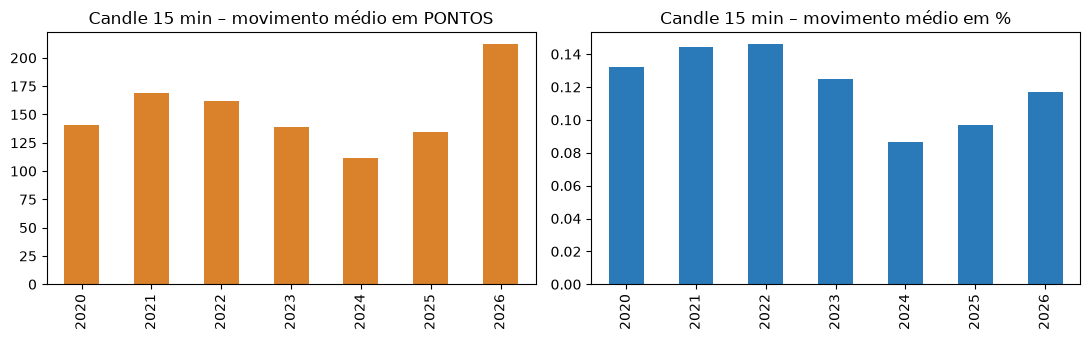

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
por_ano["|mov| médio (pts)"].plot.bar(ax=axs[0], color="#d9822b", title="Candle 15 min – movimento médio em PONTOS")
por_ano["|mov| médio (%)"].plot.bar(ax=axs[1], color="#2a7ab9", title="Candle 15 min – movimento médio em %")
for a in axs: a.set_xlabel("")
plt.tight_layout(); plt.savefig("passo02_pontos_vs_pct.png", dpi=120); plt.show()

**Decisão:** o alvo de treino é o **retorno em %** do próximo candle. Na hora de medir o dinheiro, convertemos:
$$	ext{pontos previstos} = rac{	ext{retorno previsto (\%)}}{100} 	imes 	ext{close}_t$$

## 2.2 Como é a distribuição do alvo

Retornos financeiros têm **caudas pesadas**: a maioria dos candles anda pouco, mas de vez em quando um candle anda muito.
Isso importa porque a árvore de regressão escolhe as divisões minimizando o **erro quadrático**: um único candle extremo pesa como centenas de candles normais.

In [4]:
dist = pd.DataFrame({f"{m} min": {"média %": t["ret_prox"].mean(), "desvio %": t["ret_prox"].std(),
                                    "curtose (normal=0)": t["ret_prox"].kurt(),
                                    "p1 %": t["ret_prox"].quantile(.01), "p99 %": t["ret_prox"].quantile(.99),
                                    "mín %": t["ret_prox"].min(), "máx %": t["ret_prox"].max()}
                     for m, t in treino.items()}).T
dist.round(4)

,média %,desvio %,curtose (normal=0),p1 %,p99 %,mín %,máx %
1 min,-0.0000,0.0524,15.7470,-0.1433,0.1428,-1.7943,1.2874
5 min,-0.0000,0.1150,9.5215,-0.3103,0.3122,-1.7640,2.1383
15 min,0.0002,0.1969,7.5663,-0.5287,0.5248,-1.9585,3.1775
30 min,0.0003,0.2799,6.6636,-0.7571,0.7316,-2.6240,3.4153
60 min,0.0001,0.3993,4.6258,-1.0425,1.0493,-2.5497,3.7044


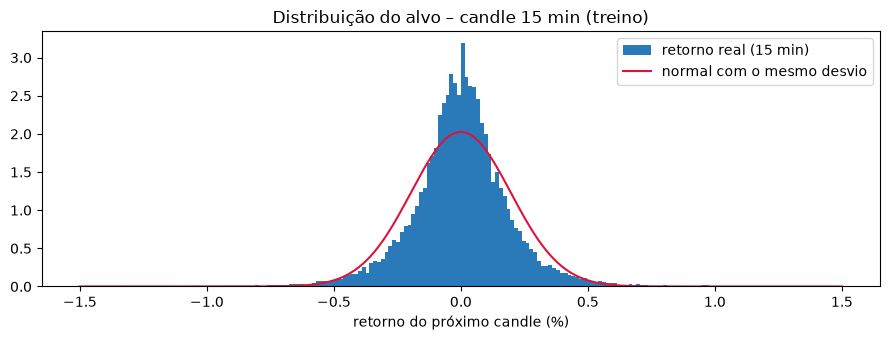

In [5]:
r = treino[15]["ret_prox"]
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(r, bins=200, range=(-1.5, 1.5), color="#2a7ab9", density=True, label="retorno real (15 min)")
x = np.linspace(-1.5, 1.5, 400)
ax.plot(x, np.exp(-x**2 / (2 * r.std()**2)) / (r.std() * np.sqrt(2 * np.pi)), "crimson", label="normal com o mesmo desvio")
ax.set_title("Distribuição do alvo – candle 15 min (treino)"); ax.set_xlabel("retorno do próximo candle (%)"); ax.legend()
plt.tight_layout(); plt.savefig("passo02_distribuicao.png", dpi=120); plt.show()

## 2.3 Existe algum sinal? Autocorrelação

Correlação entre o retorno do candle *t* e o do candle *t+1* (e *t+2*, ...). Se for ~0 em todos os candles, não há previsibilidade **linear** simples.
A árvore ainda pode achar padrões não lineares (por exemplo, "depois de candle forte no início do pregão"), mas isto calibra a expectativa: **o sinal, se existir, é fraco**.

In [6]:
ac = {}
for m, t in treino.items():
    s = t["ret_prox"]
    ac[f"{m} min"] = {f"lag {k}": s.autocorr(k) for k in range(1, 6)} | {"faixa ±2/√n": 2 / np.sqrt(len(s))}
pd.DataFrame(ac).T.round(4)

,lag 1,lag 2,lag 3,lag 4,lag 5,faixa ±2/√n
1 min,-0.0030,-0.0012,-0.0025,-0.0049,0.0012,0.0033
5 min,-0.0031,-0.0084,-0.0018,0.0040,0.0002,0.0074
15 min,-0.0018,-0.0016,0.0083,-0.0098,-0.0072,0.0130
30 min,-0.0026,-0.0153,0.0097,0.0122,-0.0168,0.0186
60 min,0.0017,0.0112,-0.0282,-0.0014,-0.0054,0.0271


## 2.4 A referência que a árvore precisa bater

Avaliação só de acerto (Fase A, sem custo e sem dinheiro), na validação 2024, de dois modelos triviais:
* **Naive** – prevê retorno 0 sempre (equivale a "não sei").
* **Média do treino** – prevê sempre o retorno médio do treino.

Métricas de previsão que vamos usar em todos os passos:
* **RMSE** – erro médio da previsão (quanto menor melhor);
* **R² fora da amostra** = 1 − EQM(modelo)/EQM(naive). Positivo = melhor que dizer "0". Em finanças, R² de 0,5% já é muito;
* **Acerto de direção** – % das vezes em que o sinal da previsão bate com o real;
* **Theil U** = √(1 − R²): a mesma informação na escala usada pela frente estatística (U < 1 ⇔ R² > 0).

In [7]:
def avaliar(prev_pct, base):
    real = base["ret_prox"].values
    eqm, eqm_naive = np.mean((real - prev_pct)**2), np.mean(real**2)
    direcao = np.sign(prev_pct)
    return pd.Series({"RMSE %": np.sqrt(eqm), "R² vs naive %": 100 * (1 - eqm / eqm_naive), "Theil U": np.sqrt(eqm / eqm_naive),
                      "acerto direção %": 100 * np.mean(direcao[direcao != 0] == np.sign(real[direcao != 0])) if (direcao != 0).any() else np.nan})

ref = {}
for m in CANDLES:
    v = valid[m]
    ref[(f"{m} min", "naive (0)")] = avaliar(np.zeros(len(v)), v)
    ref[(f"{m} min", "média do treino")] = avaliar(np.full(len(v), treino[m]["ret_prox"].mean()), v)
pd.DataFrame(ref).T.round(4)

RMSE %  R² vs naive %  Theil U  acerto direção %
1 min  naive (0)        0.0330         0.0000      1.0               NaN
       média do treino  0.0330         0.0002      1.0           46.6315
5 min  naive (0)        0.0720         0.0000      1.0               NaN
       média do treino  0.0720         0.0002      1.0           48.5862
15 min naive (0)        0.1239         0.0000      1.0               NaN
       média do treino  0.1239        -0.0039      1.0           49.1048
30 min naive (0)        0.1742         0.0000      1.0               NaN
       média do treino  0.1742        -0.0062      1.0           49.0960
60 min naive (0)        0.2380         0.0000      1.0               NaN
       média do treino  0.2380        -0.0021      1.0           49.2515

## Conclusões do Passo 2

1. **Alvo em %, não em pontos.** O movimento médio em pontos varia de 112 (2024) a 212 (2026) principalmente porque o preço subiu; em % ele é bem mais estável (0,09%–0,15%). A árvore aprende o retorno em %.
2. **Caudas pesadas.** Curtose de 7,6 no candle de 15 min (a normal tem 0). Como a árvore minimiza erro quadrático, candles extremos podem dominar as divisões.
3. **Quase nenhuma previsibilidade linear.** A autocorrelação fica dentro da faixa de ruído em todos os candles: R² de fração de 1% já seria um bom resultado.
4. **Referência a bater (Fase A):** prever zero tem R² = 0 e Theil U = 1. A árvore precisa de **R² > 0** (U < 1) na validação.
